In [ ]:
import pandas as pd
import numpy as np

s = pd.Series(['Matematicas', 'Historias', 'Economia', 'Programacion', 'Igles'])
print("-"*5, "Serie","-"*5)
print(s)

s2 = pd.Series({'Matematicas': 6.0, 'Historias': 5.2, 'Economia': 4.8, 'Programacion': 3.2, 'Igles': 6})
print("-"*5, "Serie 2","-"*5)
print(s2)
print(s2[1:2])

s3 = pd.Series({'Matematicas': 6.0, 'Historias': 5.2, 'Economia': 4.8, 'Programacion': 3.2, 'Igles': '6'})
print("-"*5, "Serie 3","-"*5)
print(s3)
print(s3[["Matematicas", "Programacion"]])
indices = ["Matematicas", "Programacion"]
print(s3[indices])

s4 = pd.Series([1,2,3,3,5])
print("-"*5, "Serie 4","-"*5)
print(s4.sum())
print(s4.cumsum())
print(s4.value_counts())
print(s4.var())
print(s4.describe())


## Data Frame

Un objeto del tipo DataFrame define un conjunto de datos estructurado en forma de tabla donde cada columna es un objeto de tipo Series, es decir, todos los datos de una misma columna son del mismo tipo, y las filas son registros que pueden contender datos de distintos tipos.

Un DataFrame contiene dos índices, uno para las filas y otro para las columnas, y se puede acceder a sus elementos mediante los nombres de las filas y las columnas.

Ejemplo. El siguiente DataFrame contiene información sobre los alumnos de un curso. Cada fila corresponde a un alumno y cada columna a una variable.

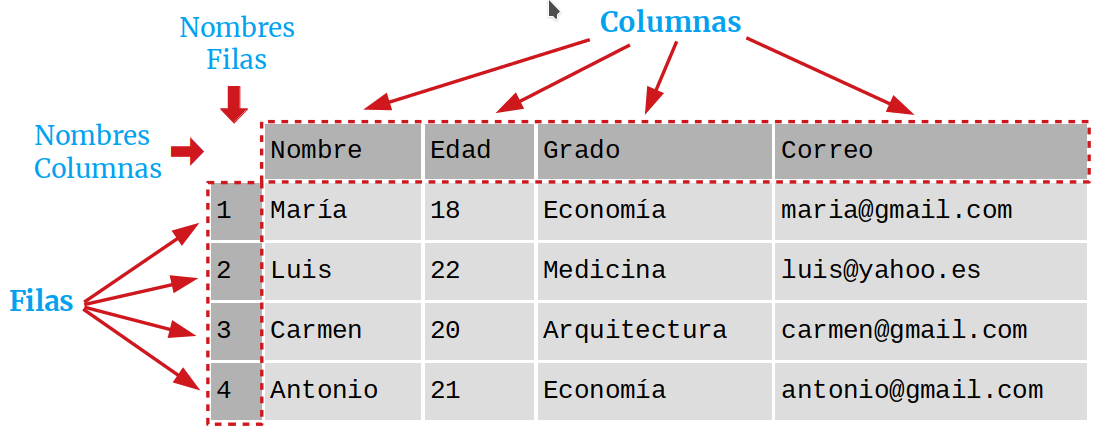

> Ejemplo de como seria en python
```Python
datos = {'nombre':['Pepe', 'marcos', 'ana'], 
         'edad':[52,32,25],
         'ciudad':['Ovideo', 'Gijon', 'Langreo']
         }
```

In [ ]:
datos = {'nombre':['María', 'Luis', 'Carmen', 'Antonio'],
         'edad':[18, 22, 20, 21],
         'grado':['Economía', 'Medicina', 'Arquitectura', 'Economía'],
         'correo':['maria@gmail.com', 'luis@yahoo.es', 'carmen@gmail.com', 'antonio@gmail.com']
         }

dataFrameDatos = pd.DataFrame(datos)
display(dataFrameDatos)

### 1. Ejercicio

Crear un DataFrame que tenga 5 registros,  que corresponden a los campos siguientes: Marca. Modelo, potencia, precio.

In [ ]:
data = {'marca':['Ford', 'Toyota', 'Opel', 'BYD', 'Peugot'],
        'modelo':['F150', 'Prius', 'Insignia', 'Model1', '308'],
        'potencia':[340, 120, 150, 210, 130],
        'precio':[15000.0, 35000.0,37000.0,27000.0,18000.0]
        }

datos = pd.DataFrame.from_dict(data)
display(datos)

Como seria si no tienes un valor en la lista de valores del diccionario

```Python
datos = pd.DataFrame.from_dict(data, orient='index').T.fillna(0)
```
Esto lo que hace es crear un DataFrame con las filas colo columnas y las columnas como filas luego hace una traspuesta de esta y rellena los datos con `None` o `np.NaN` con 0 

In [ ]:
data = {'marca':['Ford', 'Toyota', 'Opel', 'BYD', 'Peugot'],
        'modelo':['F150', 'Prius', 'Insignia', 'Model1', '308'],
        'potencia':[340, 120, 150, 210],
        'precio':[15000.0, 35000.0,37000.0,27000.0,18000.0]
        }
datos = pd.DataFrame.from_dict(data, orient='index').T.fillna(0)
display(datos)

## Creación de un DataFrame a partir de una lista de listas

Para crear un DataFrame a partir de una lista de listas con los datos de las columnas se utiliza el siguiente método:

* *``DataFrame(data=listas, index=filas, columns=columnas, dtype=tipos)``* : Devuelve un objeto del tipo DataFrame cuyas columnas son los valores de las listas de la lista *`listas`*, los nombres de *`filas`* indicados en la lista filas, los nombres de columnas indicados en la lista ``columnas`` y los tipos indicados en la lista tipos. La lista ``filas``, tiene que tener el mismo tamaño que la lista ``listas`` mientras que las listas ``columnas`` y ``tipos`` tienen que tener el mismo tamaño que las listas anidadas en ``listas``. Si no se pasa la lista de filas o de columnas se utilizan enteros empezando en 0. Si no se pasa la lista de tipos, se infiere.

In [ ]:
df = pd.DataFrame([['María', 18], ['Luis', 22], ['Carmen', 20]], columns=['Nombre', 'Edad'])
print(df)

## Creación de un DataFrame a partir de una lista de diccionarios
Para crear un DataFrame a partir de una lista de diccionarios con los datos de las filas, se utiliza el siguiente método:

* DataFrame(data=diccionarios, index=filas, columns=columnas, dtype=tipos) : Devuelve un objeto del tipo DataFrame cuyas filas contienen los valores de los diccionarios de la lista diccionarios, los nombres de filas indicados en la lista filas, los nombres de columnas indicados en la lista columnas y los tipos indicados en la lista tipos. La lista filas tiene que tener el mismo tamaño que la lista lista. Si no se pasa la lista de filas se utilizan enteros empezando en 0. Si no se pasa la lista de columnas se utilizan las claves de los diccionarios. Si no se pasa la lista de tipos, se infiere.

In [ ]:
df = pd.DataFrame([{'Nombre':'María', 'Edad':18}, {'Nombre':'Luis', 'Edad':22}, {'Nombre':'Carmen'}])
print(df)

## Creación de un DataFrame a partir de un array
Para crear un DataFrame a partir de un array de NumPy se utiliza el siguiente método:

* DataFrame(data=array, index=filas, columns=columnas, dtype=tipo) : Devuelde un objeto del tipo DataFrame cuyas filas y columnas son las del array array, los nombres de filas indicados en la lista filas, los nombres de columnas indicados en la lista columnas y el tipo indicado en tipo. La lista filas tiene que tener el mismo tamaño que el número de filas del array y la lista columnas el mismo tamaño que el número de columnas del array. Si no se pasa la lista de filas se utilizan enteros empezando en 0. Si no se pasa la lista de columnas se utilizan las claves de los diccionarios. Si no se pasa la lista de tipos, se infiere.

In [ ]:
df = pd.DataFrame(np.random.randn(4, 3), columns=['a', 'b', 'c'])
print(df)

## Creación de un DataFrame a partir de un fichero CSV o Excel
Dependiendo del tipo de fichero, existen distintas funciones para importar un DataFrame desde un fichero.

* read_csv(fichero.csv, sep=separador, header=n, index_col=m, na_values=no-validos, decimal=separador-decimal) : Devuelve un objeto del tipo DataFrame con los datos del fichero CSV fichero.csv usando como separador de los datos la cadena separador. Como nombres de columnas se utiliza los valores de la fila n y como nombres de filas los valores de la columna m. Si no se indica m se utilizan como nombres de filas los enteros empezando en 0. Los valores incluídos en la lista no-validos se convierten en NaN. Para los datos numéricos se utiliza como separador de decimales el carácter indicado en separador-decimal.

* read_excel(fichero.xlsx, sheet_name=hoja, header=n, index_col=m, na_values=no-validos, decimal=separador-decimal) : Devuelve un objeto del tipo DataFrame con los datos de la hoja de cálculo hoja del fichero Excel fichero.xlsx. Como nombres de columnas se utiliza los valores de la fila n y como nombres de filas los valores de la columna m. Si no se indica m se utilizan como nombres de filas los enteros empezando en 0. Los valores incluídos en la lista no-validos se convierten en NaN. Para los datos numéricos se utiliza como separador de decimales el carácter indicado en separador-decimal.

In [ ]:
# Importación del fichero datos-colesteroles.csv
df = pd.read_csv('https://raw.githubusercontent.com/asalber/manual-python/master/datos/colesteroles.csv', sep=';', decimal=',')
display(df.info())
display(df.head())